# BEE 4750 Mini-Project 2: Dispatching New York’s Grid Under a Carbon Price

**Names**: Gina Chen, Mikael Murphy-Rendon

**IDs**: cc2859, mm3446

> **Due Date**
>
> Friday, 11/20/26, 9:00pm

## Overview

In 2013, New York’s grid still burned coal, ran the Indian Point nuclear
plant, and had almost no solar. In this project you will model how that
grid met demand hour by hour, find the price of electricity each hour,
and ask what impact a carbon price would have made: first by changing
which plants run, and then by changing what gets built.

### Instructions

- Students in BEE 4750 may work in groups of 2; students in BEE 5750
  work individually.
- Submit a **report of no more than 4 pages**, not counting figures,
  tables, code, and references, as a PDF to Gradescope. Answer every
  numbered question in the report and label each answer with its number
  (for example, **4.1**), then tag those pages in Gradescope.
- Put your code in an appendix or submit the notebook alongside the
  report. The report should read on its own without it.
- Parts 1–4 use linear programming, shadow prices, JuMP, and
  multi-period dispatch (October 14–28 and the October 26 lab). Part 5
  uses capacity expansion (November 2).

### Load Environment

The following code loads the environment and makes sure all needed
packages are installed. This should be at the start of most Julia
scripts.

In [50]:
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

  Activating project at `~/BEE 4750/mp02`


In [51]:
using JuMP
using HiGHS
using CSV
using DataFrames
using Statistics
using Plots
using Measures

# Add in for P4.1 
Pkg.add("PrettyTables")
using PrettyTables

   Resolving package versions...
  No Changes to `~/BEE 4750/mp02/Project.toml`
  No Changes to `~/BEE 4750/mp02/Manifest.toml`


## The System

We treat New York as a single node (no transmission limits) and model
every hour of 2013.

**Demand** is NYISO’s hourly load for 2013, summed over its eleven
zones. It ranges from about 12 GW overnight to a 34 GW summer peak.

**The existing fleet** is New York’s summer 2013 generating capability,
grouped by type. Each plant type can generate up to its available
capacity in each hour. The thermal types (nuclear, coal, steam, combined
cycle, and combustion turbines) can also change their output by at most
their ramp fraction of capacity from one hour to the next. Hydro, wind,
and solar have no ramp limit.

| Type | Capacity (MW) | Variable cost (\$/MWh) | CO<sub>2</sub> (t/MWh) | Ramp (per hour) | Availability |
|:-----------|-----------:|-----------:|-----------:|-----------:|:-----------|
| Nuclear | 5,411 | 8 | 0 | 0.25 | 88% |
| Hydro | 4,276 | 0 | 0 | – | budget |
| Coal | 1,548 | 24 | 1.00 | 0.70 | 100% |
| Oil and gas steam | 9,576 | 45 | 0.58 | 0.70 | 100% |
| Combined cycle | 8,991 | 30 | 0.43 | 0.70 | 100% |
| Combustion turbine | 4,911 | 40 | 0.55 | 1 | 100% |
| Wind | 1,634 | 0 | 0 | – | profile |
| Solar | 31.5 | 0 | 0 | – | profile |

Table 1: New York’s 2013 generating fleet.

The fleet file has a ninth row, combined cycle with carbon capture, with
no capacity: New York had none in 2013. It generates nothing in Parts
1–4 and becomes an option in Part 5.

**Hydro** can be dispatched in any hour up to its capacity, but its
total generation over the year cannot exceed **24,572 GWh**, New York’s
hydro generation in 2012. Most of that capacity is the New York Power
Authority’s plants on the Niagara and St. Lawrence rivers. At Niagara, a
1950 treaty with Canada sets how much of the river’s flow must go over
the falls rather than through the turbines, which limits the water
available for power. Water used in one hour is not available in another.

**Wind and solar** follow hourly capacity-factor profiles, rescaled so
their annual averages match New York’s observed values: 23.4% for wind
and 16.5% for solar.

**Non-served energy** is allowed but penalized at \$10,000/MWh, so the
problem is always feasible. A good plan should have none.

> **Data and Simplifications**
>
> Capacities are from NYISO’s *2013 Load & Capacity Data* report (the
> “Gold Book”), Table III-3a, summer capability; wind and solar use
> nameplate capacity. Coal, combined cycle, and combustion turbine
> variable costs are roughly what these plants cost to run at 2012–13
> fuel prices, and their emissions are the values used in lecture; the
> others are course assumptions. The wind capacity factor is from the
> Gold Book’s 2012 energy for wind plants in service all year, and the
> solar capacity factor is the Long Island Solar Farm’s in NYISO’s 2024
> Gold Book. The ramp fractions are hourly limits: coal’s and combined
> cycle’s are the rates of the large units in the RTS-GMLC test system
> (about 4 MW per minute on a 350 MW unit), steam is assumed to match
> coal, combustion turbines can reach full output within an hour, and
> nuclear’s is a course assumption.
>
> The model leaves out imports (New York imported roughly 15% of its
> electricity), pumped storage (1,407 MW), about 400 MW of small biomass
> and waste plants, and transmission limits between zones.

For comparison, in 2012 New York generated 139,137 GWh in-state: 29.4%
nuclear, 17.7% hydro, 2.2% wind, and 48.1% fossil, of which coal was
3.1%.

The data, ready to use:

In [52]:
# Statewide hourly demand: the sum of NYISO's eleven load zones [MW]
load_data = DataFrame(CSV.File("data/2013_hourly_load_NY.csv"))
zones = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K"]
demand = zeros(nrow(load_data))
for zone in zones
    demand .+= load_data[:, zone]
end

# Hourly wind and solar capacity factors, rescaled to New York's annual averages
profiles = DataFrame(CSV.File("data/wind_solar_capacity_factors.csv"))
wind_cf = profiles.Wind .* (0.234 / mean(profiles.Wind))
solar_cf = profiles.Solar .* (0.165 / mean(profiles.Solar))

# The existing fleet, as in the table above. Wind and solar availability come
# from the hourly profiles, not the Availability column. RampFraction is missing
# for hydro, wind and solar, which have no ramp limit. The last row, combined
# cycle with carbon capture, has no capacity until Part 5.
fleet = DataFrame(CSV.File("data/nyca_2013_fleet.csv"))

hydro_budget = 24_572_000   # annual hydro energy [MWh]
nse_cost = 10_000           # penalty on non-served energy [$/MWh]

10000

## Problems (Total: 100 Points)

### Part 1: Formulate the Dispatch Problem (15 points) - Gina

#### Problem 1.1 (15 points) - Gina 

Formulate a linear program that decides how much each plant type
generates in every hour of 2013 to meet demand at the lowest total
variable cost. Define your decision variables (with units), objective,
and constraints: meeting demand each hour, each plant’s hourly
availability, ramping limits for the thermal types, and the hydro energy
budget. Explain each constraint in a sentence.

### Answer to Problem 1.1 
<div class="image-box">
   <img src='Answer to Problem 1.1.jpeg'>
</div>


### Part 2: Dispatching New York in 2013 (20 points) - Mikael 

#### Problem 2.1 (10 points) 

Solve your model in JuMP with no carbon tax. Report the total variable
cost, annual CO<sub>2</sub> emissions, each plant type’s share of
generation, and any non-served energy. Compare your generation shares
with New York’s actual 2012 shares above, and give two reasons for the
largest differences.

**Answer:**<br>
Total Variable Cost: 3.15 billion dollars<br>
Total CO2 Emissions: 49.01 million tonnes<br>
Total Non-Served Energy: 0.0 MWh<br>

|Plant Type | Generated Shares(%)| Difference from Actual (%)|
|:---|:---|---:|
|Nuclear               | 25.51|−3.89|
|Hydro                 | 15.03|-2.67|
|Coal                  | 8.29|+5.19|
|Steam                 | 0.77|N/A|
|CombinedCycle         | 44.54|N/A|
|CombustionTurbine     | 3.78|N/A|
|Wind                  | 2.05|-0.15|
|Solar                 | 0.03|N/A|
|Fossils combined (minus coal)|49.09|4.09|

Comparison:<br>
In 2012 New York generated 29.4% nuclear, 17.7% hydro, 2.2% wind, and 48.1% fossil, of which coal was 3.1%, which is more nuclear, hydro, and wind but less coal. Since NY imports about 15% of its electricity in reality and the model doesn't consider this, the plants must compensate for the remaining electricity demand. As nuclear and hydro are running at capacity, fossil-fuel based generation needs to be increased. Additionally, the optimization is considering a simplified merit order based on variable cost, where coal has the lowest variable cost at \$24/MWh so it can be used more readily in this model. Coal will likely be used differently if the model considers the fixed cost of operating a coal plant.

In [53]:
n_types=8
n_hours = 8760
availability = zeros(n_types, n_hours) # availability_g_t for share of capacity usable in hour t 
types = fleet.Type
for g in 1:n_types # loop through all plant g 
    for t in 1:n_hours # loop through all time 
        if types[g] == "Wind"
            availability[g, t] = wind_cf[t]
        elseif types[g] == "Solar"
            availability[g, t] = solar_cf[t]
        else
            availability[g, t] = fleet.Availability[g] # Given percentage in table 
        end
    end
end

model = Model(HiGHS.Optimizer)
set_silent(model)
#add variables
@variable(model, y[g in 1:n_types, t in 1:n_hours] >= 0) # MW generation for each generator every hour
@variable(model, nse[t in 1:n_hours] >= 0) # MW amount of nonserved energy every hour

#objective -> lowest cost of generation + non-served energy
@objective(model, Min, sum(fleet.VarCost[g] * y[g, t] for g in 1:n_types, t in 1:n_hours) + nse_cost * sum(nse))

#constraints
@constraint(model, load[t in 1:n_hours], sum(y[g, t] for g in 1:n_types) + nse[t] >= demand[t]) # demand every hour 
@constraint(model, avail_con[g in 1:n_types, t in 1:n_hours], y[g, t] <= fleet.Capacity[g] * availability[g,t]) # limit on availability
#non-negativity included in variable definition
@constraint(model, cap_max[g in 1:n_types, t in 1:n_hours],y[g,t]<=fleet.Capacity[g]) # limit on capacity
for g in 1:n_types
    if !ismissing(fleet.RampFraction[g])
        ramp = fleet.RampFraction[g] * fleet.Capacity[g]
        for t in 1:(n_hours - 1)
            @constraint(model, y[g, t+1] - y[g, t] <= ramp)
            @constraint(model, y[g, t] - y[g, t+1] <= ramp)
        end
    end
end
@constraint(model, hydro_con, sum(y[2, t] for t in 1:n_hours) <= hydro_budget) #yearly hydro generation limit

optimize!(model)
@show termination_status(model)
#@show objective_value(model)
total_cost = objective_value(model)
total_nse = sum(value.(nse))
gen_by_type = [sum(value(y[g, t]) for t in 1:n_hours) for g in 1:n_types]
total_gen = sum(gen_by_type)
shares = (gen_by_type ./ total_gen) .* 100
total_co2 = sum(gen_by_type[g] * fleet.Emissions[g] for g in 1:n_types)

println("Total Variable Cost (\$): ", round(total_cost, digits=2))
println("Total CO2 Emissions (tonnes): ", round(total_co2, digits=2))
println("Total Non-Served Energy (MWh): ", round(total_nse, digits=2))
println("\nGeneration Shares (%):")
for g in 1:n_types
    println(rpad(fleet.Type[g], 22), ": ", round(shares[g], digits=2), "%")
end

termination_status(model) = MathOptInterface.OPTIMAL
Total Variable Cost ($): 3.14811306741e9
Total CO2 Emissions (tonnes): 4.900927684e7
Total Non-Served Energy (MWh): 0.0

Generation Shares (%):
Nuclear               : 25.51%
Hydro                 : 15.03%
Coal                  : 8.29%
Steam                 : 0.77%
CombinedCycle         : 44.54%
CombustionTurbine     : 3.78%
Wind                  : 2.05%
Solar                 : 0.03%


#### Problem 2.2 (10 points) 

Plot hourly generation by plant type, stacked, for one week in July.
Explain how the model uses hydro, given its annual budget.

**Answer:** 
Hydro has a variable cost of \$0/MWh, can be dispatched in any hour to its capacity, and is available year-round as long as it doesn't exceed the state budget. This allows the model to use the hydro plant as a way to meet a base level of the demand consistently (as it fluctuates in use proportional to demand). During periods of high demand (like a July midday), hydro-generated energy is preferred because of its low cost and lack of ramping requirement, but during low-demand periods (like overnight), the model will use other cheap options to prevent the hydro budget from maxing out too early in the year.

Figure 1. Generation by plant type for one week of July in NY


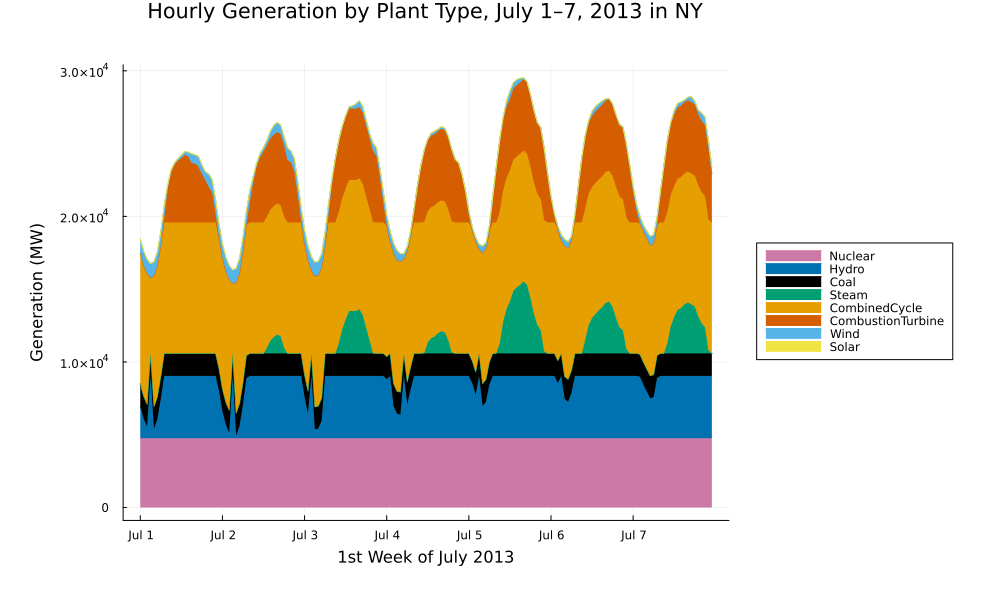

In [54]:
#2013 wasn't a leap year, so July 1 is day 181 and July 7 is day 188
july_hours = (181 * 24 + 1):(188 * 24)  # July 1–7, inclusive

generation = [value(y[g, t]) for t in july_hours, g in 1:n_types]
generators = 1:length(july_hours)
generators_colors = palette(:okabe_ito)[[7,5,8,3,1,6,2,4]]

println("Figure 1. Generation by plant type for one week of July in NY")
areaplot(generators, generation;
    title="Hourly Generation by Plant Type, July 1–7, 2013 in NY",
    xlabel="1st Week of July 2013",
    ylabel="Generation (MW)",
    color = permutedims(generators_colors),
    label=permutedims(fleet.Type),
    xticks=(1:24:168, ["Jul 1", "Jul 2", "Jul 3", "Jul 4", "Jul 5", "Jul 6", "Jul 7"]),
    legend=:outerright,
    margin=10mm,
    size=(1000, 600))

### Part 3: The Value of Water (10 points) - Mikael 

#### Problem 3.1 (10 points)

Report the shadow price of the hydro budget and interpret it. Suppose
enough extra water could be diverted through the Niagara turbines to
generate one more MWh over the year: what would that MWh be worth, and
why that value? Be careful with the sign.

**Answer:** The shadow price of the hydro budget is \$30/MWh, which is the amount of money that the total variable cost is reduced by for every 1 MWh of hydro energy added to the hydro budget. If one more MWh could be generated over the year, it would be worth $30 dollars because it would replace the 1 MWh generated by a more expensive type of generation.

In [55]:
display(shadow_price.(hydro_con))

-30.0

### Part 4: A Carbon Tax (25 points) - Gina 

#### Problem 4.1 (15 points) - Gina 

Add a carbon tax of $\tau$ dollars per tonne of CO<sub>2</sub> to your
model, and show how it enters your objective. Solve the dispatch problem
with taxes of \$0, \$20, \$40, \$60, and \$100 per tonne, and report
annual emissions and each fossil plant type’s share of generation at
each tax in a table. Between which taxes do emissions drop, and which
plant type moves ahead of coal in each? Why does coal keep running after
it falls behind combined cycle plants?

### Answer to P4.1 
Emissions drop between taxes (dollars per tonne) 
- from 0 to 20, where the combined cycle plant moves ahead of coal (increases from 44.5 to 47.7%)
- from 20 to 40, where the combustion turbine plant moves ahead 
and from 40 to 60, where the steam plant moves ahead of coal. 

Coal keeps running after it falls behind combined cycle plants (this happens when carbon tax goes from $0 to $20 per tonne) because coal is still the cheapest next generation, as the combined cycle reaches it capacity. As seen in the fleet table and from our result table, combined cycle plant reaches it capacity of 8991 MW as it has a staganated percentage of 47.7 share of generation (after tax reaches $20 and beyond). Then, at this carbon tax rate of $20/tonnecoal has a total variable cost and carbon emission cost of 24 + 20*1 = $44/MWh while the total cost for steam plant is 45 + 20(0.7) = 59 > 44, combustion turbine is 40 + 20(0.55) = 51 > 44. Also, to double check here, combined cycle plant has a toatl cost for each hour of 30 + 20(0.43) = 38.6 < 44, which is also why there is a increase of combustion turbine plant generation (and the coal decreased to compensate). Since coal has the next lowest cost for each  unit of generaetion, coal would keep running, according to merit order. 

<div class="image-box">
   <img src='Answer to Problem 4.1.jpeg'>
</div>


In [56]:
total_types = nrow(fleet) # Get 9 plants = number of rows of nyca csv = fleet table
total_hours = length(demand) 
types = fleet.Type # plant types
hydro = findfirst(==("Hydro"), types) # Get row number of hydro
# print(hydro) # ouput 2, match second row under type in excel  

availability = zeros(total_types, total_hours) # availability_g_t for share of capacity usable in hour t 

for g in 1:total_types # loop through all plant g 
    for t in 1:total_hours # loop through all time 
        if types[g] == "Wind"
            availability[g, t] = wind_cf[t]
        elseif types[g] == "Solar"
            availability[g, t] = solar_cf[t]
        else
            availability[g, t] = fleet.Availability[g] # Given percentage in table 
        end
    end
end

# Add in carbon tax 
# Need to change for differnet tau given 
function run_dispatch(tau)
    model = Model(HiGHS.Optimizer)
    set_silent(model)

   
    @variable(model, y[g in 1:n_types, t in 1:n_hours] >= 0)  # Referenced lecture codes 
    @variable(model, nse[t in 1:n_hours] >= 0)

    ### Updated objective for variable cost + non-served energy cost + carbon tax
    @objective(model, Min, sum((fleet.VarCost[g] + tau * fleet.Emissions[g]) * y[g, t] for g in 1:n_types, t in 1:n_hours) + nse_cost * sum(nse))

    ### constaints 
    @constraint(model, load[t in 1:n_hours], sum(y[g, t] for g in 1:n_types) + nse[t] >= demand[t]) # Deamnd 
    @constraint(model, avail_con[g in 1:n_types, t in 1:n_hours], y[g, t] <= fleet.Capacity[g] * availability[g, t]) # limit on availability
    # For ramping constraints, use P1.1 defined constriant inequalities 
    for g in 1:n_types
        if !ismissing(fleet.RampFraction[g]) # For types that have been given Ramp, use the ramp 
            ramp = fleet.RampFraction[g] * fleet.Capacity[g]   
            for t in 1:(n_hours - 1)
                @constraint(model, y[g, t+1] - y[g, t] <= ramp)
                @constraint(model, y[g, t] - y[g, t+1] <= ramp)
            end
        end
    end
    # Contraint for hydro 
    @constraint(model, hydro_con, sum(y[hydro, t] for t in 1:n_hours) <= hydro_budget)



    optimize!(model)

    # Find total annual generation for each 
    gen = zeros(n_types)
    for g in 1:n_types
        gen[g] = sum(value(y[g, t]) for t in 1:n_hours)
    end
    # Find emission values for each 
    emissions = sum(fleet.Emissions[g] * gen[g] for g in 1:n_types)   
    nse_total = sum(value(nse[t]) for t in 1:n_hours)
    
    # Need to report emission
    return (gen = gen, emissions = emissions, nse = nse_total, cost = objective_value(model))
end

run_dispatch (generic function with 1 method)

In [57]:
# Run to get results for tau of 0 to 100 + report 
carbon_tax = [0, 20, 40, 60, 100]


# Need a dataframe for pretty table 
# Get fossil plants from  fleet table
coal_row = findfirst(==("Coal"), types)
steam_row = findfirst(==("Steam"), types)
combined_row = findfirst(==("CombinedCycle"), types)
combustion_row = findfirst(==("CombustionTurbine"), types)

emissions_col = Float64[]
coal_col = Float64[]
steam_col = Float64[]
combined_col = Float64[]
combustion_col = Float64[]
nse_col = Float64[]

# Solve + store for each tax 
for tau in carbon_tax
    r = run_dispatch(tau)
    total = sum(r.gen) # Annual generation 

    push!(emissions_col, round(r.emissions/ 1e6, digits=2))  # Convert to Million
    # Get % for reporting for fossil plants 
    push!(coal_col, round(100 * r.gen[coal_row]/ total, digits=1))
    push!(steam_col,round(100 * r.gen[steam_row]/ total, digits=1))
    push!(combined_col, round(100 * r.gen[combined_row]/ total, digits=1))
    push!(combustion_col, round(100 * r.gen[combustion_row]/ total, digits=1))
    push!(nse_col, round(r.nse, digits=1))
end


results_table = DataFrame(
    "Tax" => carbon_tax,
    "Emissions" => emissions_col, # MtCO2/yr
    "Coal" => coal_col, # in % 
    "Steam" => steam_col, # in %
    "Combined" => combined_col, # in %
    "Combustion"=> combustion_col, # in %
    "Non-served" => nse_col, # MWh
)

pretty_table(results_table) # Cannot fit units in table, otherwise columns got omitted

┌───────┬───────────┬─────────┬─────────┬──────────┬────────────┬────────────┐
│   Tax │ Emissions │    Coal │   Steam │ Combined │ Combustion │ Non-served │
│ Int64 │   Float64 │ Float64 │ Float64 │  Float64 │    Float64 │    Float64 │
├───────┼───────────┼─────────┼─────────┼──────────┼────────────┼────────────┤
│     0 │     49.01 │     8.3 │     0.8 │     44.5 │        3.8 │        0.0 │
│    20 │     46.08 │     5.1 │     0.8 │     47.7 │        3.8 │        0.0 │
│    40 │     42.72 │     0.6 │     0.8 │     47.7 │        8.3 │        0.0 │
│    60 │     42.32 │     0.0 │     1.3 │     47.7 │        8.3 │        0.0 │
│   100 │     42.32 │     0.0 │     1.3 │     47.7 │        8.3 │        0.0 │
└───────┴───────────┴─────────┴─────────┴──────────┴────────────┴────────────┘


#### Problem 4.2 (10 points) - Gina

Is there any tax that brings emissions below 40 million tonnes per year
by changing only which existing plants run? Identify the lowest
emissions redispatch can reach, and explain what sets that floor.

### Answer to P4.2 
Since the emissions for tax of $60 and $100 are both at 42.32 million tonnes per year, I suspect that the emissions might stablize at this value instead of keeping to decrease. When double checking with even larger tau value of $150, $300, $600, the emissions are still 42.32 million tonne per year. Thus, **there is no any that would bring emission below 40 million tonnes per year** by changing only which exisitn platns run. **The lowest emissions redispatch can reach is 42.32 million tonnes per year**. Since the redipatch has already allows the lowest emission plants to run, the further increase of tax would not affect the emissions because these high emissions are required to run to help total generation reaches the demand. 
# Ask in OH to seek better explaination for what sets the lowest emission  

In [58]:
for tau in [150, 300, 600]
    r = run_dispatch(tau)
    println("Tax = ", tau, ": ", round(r.emissions / 1e6, digits=2), " Mt")
end;

Tax = 150: 42.32 Mt
Tax = 300: 42.32 Mt
Tax = 600: 42.32 Mt


### Part 5: Building New Capacity (30 points) - both!

The state can now build six kinds of new capacity: combined cycle,
combustion turbines, wind, solar, hydro, and combined cycle with carbon
capture. New capacity behaves like the existing plants of the same type:
the same variable cost, emissions, and availability, and for the gas
plants the same ramp fraction. Two of the six need more detail:

- **Hydro.** The only sites are existing dams that have no turbines, so
  at most 295 MW can be built. We assume each MW of new hydro generates,
  on average, as much as each MW of existing hydro: each new MW raises
  the annual hydro generating capacity by 24,572,000 MWh ÷ 4,276 MW ≈
  5,746 MWh.
- **Combined cycle with carbon capture.** This is the fleet file’s last
  row. It captures 90% of its CO<sub>2</sub>, so it emits 0.05 t/MWh. It
  costs \$39/MWh to run, more than a combined cycle plant, because it
  burns more gas and pays to move and store the CO<sub>2</sub> it
  captures.

Annualized costs of new capacity are in `data/new_capacity_costs.csv`
(in \$ per MW of capacity per year): `Cost2013` is from 2013 cost
estimates and `CostToday` from 2025 ones.

In [59]:
new_costs = DataFrame(CSV.File("data/new_capacity_costs.csv"))
hydro_build_limit = 295   # most new hydro that can be built [MW]

295

> **New Capacity: Data and Cautions**
>
> The annualized costs are capital costs from the U.S. Energy
> Information Administration’s 2013 and 2025 reports on new generating
> plants, spread over 30 years at 7%, plus fixed operating costs. The
> 295 MW of hydro is Oak Ridge National Laboratory’s 2012 estimate of
> the capacity that New York’s dams without turbines could support.
> Capture’s variable cost of \$39/MWh includes about \$4.50/MWh to move
> and store the 0.45 t of CO<sub>2</sub> it captures from each MWh, at
> \$10 per tonne.
>
> Keep two things in mind when you interpret your results. First, the
> 2013 cost of capture is an estimate for a kind of plant that had not
> been built at commercial scale. Second, the two reports describe
> different hydro plants, 500 MW in 2013 and 100 MW in 2025, so part of
> the increase in hydro’s cost between them comes from comparing a
> larger plant with a smaller one, not from a change in what the same
> plant costs.

#### Problem 5.1 (8 points) - Mikael 

Extend your model to include build decisions, using 2013 costs. Explain
what changes in the objective and the constraints. With no emissions
policy, what does the model build, and why? Compare the cost of a MWh
from new wind with the cost of the fuel it would replace.

**Answer:**<br>
First, we added a new decision variable ($k_g$) for the additional capacity of the combined cycle, combustion turbines, wind, solar, hydro, and combined cycle with carbon capture generators. Then, we changed the objective function by adding the sum of the additional capacities multiplied by the 2013 build costs. For the constraints, the hourly availability, max capacity, ramping constraints,  annual hydro budget all had to change. The hourly availability was changed to consider the availability of the existing capacity and additional capacity combined, the max capacity was changed to consider the total capacity after building, the ramping constraint were changed similarly to consider ramping by total capacity, and the annual hydro budget was adjusted to include the new hydro capacity by additional capacity built. We also added a constraint on the additional hydro generation based on the given 295 MW build limit.<br>
Without an emissions policy, the model does not build any new capacity. Building additional capacity at the 2013 costs is more expensive than using a fuel-based generator, so the model would never choose to build more. For example, at the 2013 costs, additional wind costs \$106/MWh, which is much 2-4x greater than any existing plants' variable costs (\$24-45/MWh for fuel), so there is no reason to build new capacity when existing plants are cheaper.

In [68]:
n_types=9
n_hours = 8760
availability = zeros(n_types, n_hours) # availability_g_t for share of capacity usable in hour t 
types = fleet.Type
for g in 1:n_types # loop through all plant g 
    for t in 1:n_hours # loop through all time 
        if types[g] == "Wind"
            availability[g, t] = wind_cf[t]
        elseif types[g] == "Solar"
            availability[g, t] = solar_cf[t]
        else
            availability[g, t] = fleet.Availability[g] # Given percentage in table 
        end
    end
end
build_rows = Int[]
build_cost = zeros(n_types)

for i in eachindex(new_costs.Type)
    g = findfirst(==(new_costs.Type[i]), types)
    if g === nothing
        error("No fleet row for build type $(new_costs.Type[i])")
    end
    push!(build_rows, g)
    build_cost[g] = new_costs.Cost2013[i]
end

model = Model(HiGHS.Optimizer)
set_silent(model)
@variable(model, y[g in 1:n_types, t in 1:n_hours] >= 0) # MW generation for each generator every hour
@variable(model, nse[t in 1:n_hours] >= 0) # MW amount of nonserved energy every hour
@variable(model, k[g in 1:n_types] >= 0) # MW of new capacity for each generator type

@objective(model, Min, sum(fleet.VarCost[g] * y[g, t] for g in 1:n_types, t in 1:n_hours) 
        + nse_cost*sum(nse) + sum(build_cost[g] * k[g] for g in 1:n_types)) 
@constraint(model, no_build[g in setdiff(1:n_types, build_rows)], k[g] == 0) # no new capacity for plants not in the build list
@constraint(model, load[t in 1:n_hours], sum(y[g, t] for g in 1:n_types) + nse[t] >= demand[t]) # demand every hour 
@constraint(model, avail_con[g in 1:n_types, t in 1:n_hours], y[g, t] <= (fleet.Capacity[g]+k[g]) * availability[g,t]) # limit on availability
@constraint(model, cap_max[g in 1:n_types, t in 1:n_hours],y[g,t]<=fleet.Capacity[g]+k[g]) # limit on capacity
for g in 1:n_types
    if !ismissing(fleet.RampFraction[g])
        ramp = fleet.RampFraction[g] * (fleet.Capacity[g] + k[g])
        for t in 1:(n_hours - 1)
            @constraint(model, y[g, t+1] - y[g, t] <= ramp)
            @constraint(model, y[g, t] - y[g, t+1] <= ramp)
        end
    end
end
hydro= findfirst(==("Hydro"), types)
@constraint(model, hydro_con, sum(y[hydro, t] for t in 1:n_hours) <= hydro_budget+(hydro_budget/fleet.Capacity[hydro])*k[hydro]) #yearly hydro generation limit
@constraint(model, hydro_build_limit_cap, k[hydro] <= hydro_build_limit) # limit on new hydro capacity
optimize!(model)
@show termination_status(model)
@show objective_value(model)

variable_cost = sum(
    fleet.VarCost[g] * value(y[g, t])
    for g in 1:n_types, t in 1:n_hours
)
capacity_cost = sum(build_cost[g] * value(k[g]) for g in 1:n_types)
total_nse = sum(value(nse[t]) for t in 1:n_hours)
nse_penalty = nse_cost * total_nse
total_cost = objective_value(model)

println("Total annual system cost : \$", round(total_cost, digits=2))
println("Variable generation cost : \$", round(variable_cost, digits=2))
println("Annualized capacity cost : \$", round(capacity_cost, digits=2),"/year")
println("Non-served energy penalty : \$", round(nse_penalty, digits=2))

println("\nNew capacity built (MW):")
for g in build_rows
    println(fleet.Type[g], ": ", round(value(k[g]), digits=2))
end

termination_status(model) = MathOptInterface.OPTIMAL
objective_value(model) = 3.1481130674059825e9
Total annual system cost : $3.14811306741e9
Variable generation cost : $3.14811306741e9
Annualized capacity cost : $0.0/year
Non-served energy penalty : $0.0

New capacity built (MW):
CombinedCycle: 0.0
CombustionTurbine: 0.0
Wind: 0.0
Solar: 0.0
Hydro: 0.0
CombinedCycleCapture: 0.0


#### Problem 5.2 (10 points) - Gina

Cap annual emissions at 40 million tonnes, still with 2013 costs. What
does the model build, what does the system cost, and what is the shadow
price of the cap? Explain what the new plants replace.

### Answer to P5.2 

# TBD after 5.1 model is built 

#### Problem 5.3 (12 points) - Mikael  

Repeat 5.2’s capped problem with today’s costs. What gets built now, and
what is the shadow price of the same cap? Then remove the cap and
instead impose a carbon tax equal to that shadow price. Compare the two
solutions, and explain the result using what you know about shadow
prices. What does the change from 5.2 tell you about the role of a
carbon price when technology costs fall?

> **Working With JuMP Output**
>
> `value.(x)` returns a JuMP container; use `value.(x).data` or index it
> with `value(x[g, t])` to get plain numbers for plotting. End cells
> that build large sets of variables or constraints with a semicolon to
> suppress long printed output. For a constraint `c`, `shadow_price(c)`
> reports how the objective changes as the constraint is relaxed; check
> its sign against your intuition. `fleet.RampFraction` is `missing` for
> the types with no ramp limit; test for that with `ismissing`.

## References

List any external references consulted, including classmates.

- https://eroots.tech/glossary/expected-unserved-energy-eue Reference for understanding non-served energy
- https://docs.julialang.org/en/v1/manual/missing/ reference for P4.1 